In [ ]:
import pandas as pd
df = pd.read_csv("loan_prediction_dataset.csv")
print(df.shape)
df.head()



(2000, 7)


,Age,Income,Credit_Score,Loan_Amount,Loan_Term,Employment_Status,Loan_Approved
0,56,81788,334,15022,48,Employed,0
1,69,102879,781,21013,24,Self-Employed,1
2,46,58827,779,39687,60,Self-Employed,0
3,32,127188,364,16886,24,Unemployed,0
4,60,25655,307,26256,36,Unemployed,0


In [ ]:
df.info()
print(df.isna().sum())          # missing values
print(df["Loan_Approved"].value_counts())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Age                2000 non-null   int64 
 1   Income             2000 non-null   int64 
 2   Credit_Score       2000 non-null   int64 
 3   Loan_Amount        2000 non-null   int64 
 4   Loan_Term          2000 non-null   int64 
 5   Employment_Status  2000 non-null   object
 6   Loan_Approved      2000 non-null   int64 
dtypes: int64(6), object(1)
memory usage: 109.5+ KB
Age                  0
Income               0
Credit_Score         0
Loan_Amount          0
Loan_Term            0
Employment_Status    0
Loan_Approved        0
dtype: int64
Loan_Approved
0    1658
1     342
Name: count, dtype: int64


,Age,Income,Credit_Score,Loan_Amount,Loan_Term,Loan_Approved
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,43.805500,84533.585000,577.055000,25460.315000,35.47800,0.171000
std,14.929203,37771.169751,157.525951,14116.737774,16.98587,0.376603
min,18.000000,20155.000000,300.000000,1060.000000,12.00000,0.000000
25%,31.000000,50925.250000,440.000000,13444.250000,24.00000,0.000000
50%,44.000000,84073.500000,578.500000,25446.000000,36.00000,0.000000
75%,56.000000,117523.250000,715.250000,37949.250000,48.00000,0.000000
max,69.000000,149992.000000,849.000000,49994.000000,60.00000,1.000000


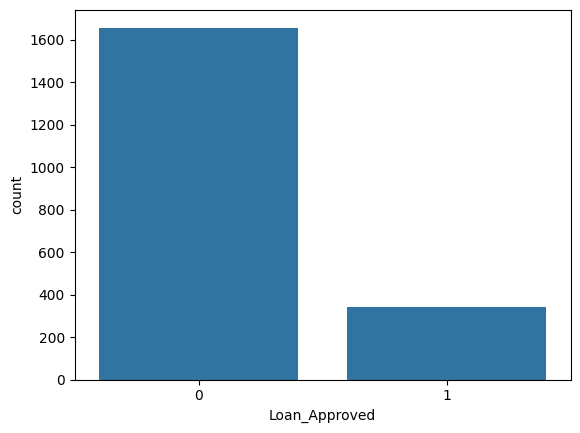

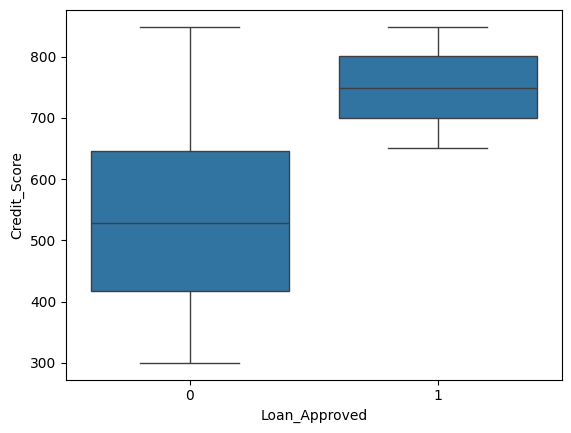

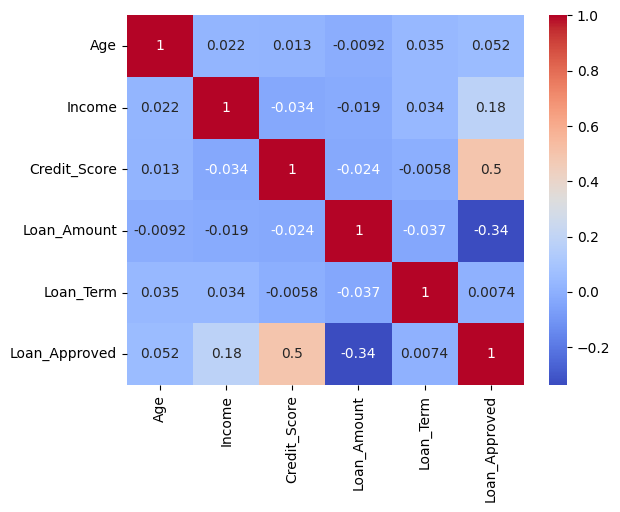

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x="Loan_Approved", data=df); plt.show()
sns.boxplot(x="Loan_Approved", y="Credit_Score", data=df); plt.show()
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm"); plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.get_dummies(df, columns=["Employment_Status"], drop_first=True)

X = df.drop("Loan_Approved", axis=1)
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
}

results = []
for name, m in models.items():
    m.fit(X_train_s, y_train)
    pred = m.predict(X_test_s)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1
1,Decision Tree,1.0000,1.000000,1.000000,1.000000
2,Random Forest,0.9975,1.000000,0.985294,0.992593
3,KNN,0.9625,0.907692,0.867647,0.887218
0,Logistic Regression,0.9150,0.765625,0.720588,0.742424


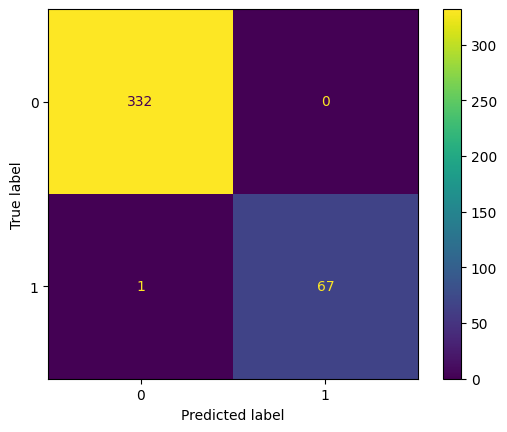

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       332
           1       1.00      0.99      0.99        68

    accuracy                           1.00       400
   macro avg       1.00      0.99      1.00       400
weighted avg       1.00      1.00      1.00       400



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
best = models["Random Forest"]          # change to whichever scored best
pred = best.predict(X_test_s)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(); plt.show()
print(classification_report(y_test, pred))

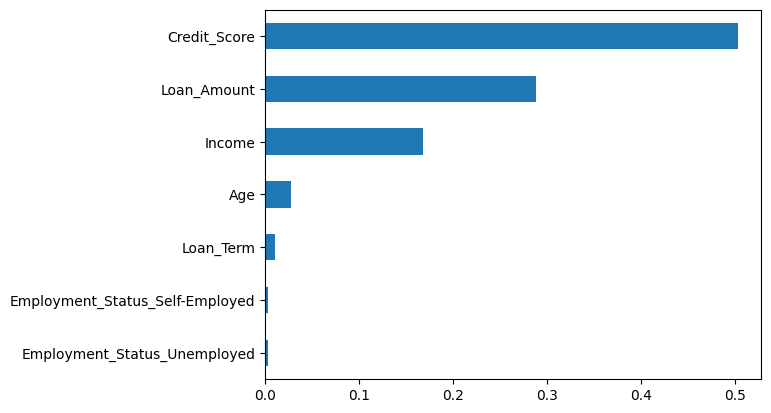

In [ ]:
pd.Series(best.feature_importances_, index=X.columns).sort_values().plot(kind="barh"); plt.show()